# Week 11B: Make a smooth DSM from LiDAR

We will use two Philadelphia LAS files, create a digital surface model with PDAL, and smooth isolated bright pixels.

A **DSM** includes roofs, trees, and ground. Elevations are relative to a vertical datum; they are not building heights above ground.

<a href="lecture-11B.ipynb" download>Download notebook</a> · [Previous: Visualization II](Visualizing%20Large%20Data-Lec2.html)


## What is LiDAR?

**LiDAR** means **Light Detection and Ranging**. It is an active sensor: it sends laser pulses and measures the time taken for reflected light to return. Airborne systems combine these distances with GNSS positioning and an inertial measurement unit (IMU) to locate returns in three dimensions. Unlike a photograph, the basic output is a collection of measured points. See [NOAA's introduction to LiDAR](https://oceanservice.noaa.gov/geodesy/lidar.html).

### How does a pulse become a 3D point?

The pulse travels to the surface and back, so range is half the round-trip distance: **distance = speed of light × travel time / 2**. Sensor position, viewing direction, and range locate the point. The illustration is schematic, not to scale.


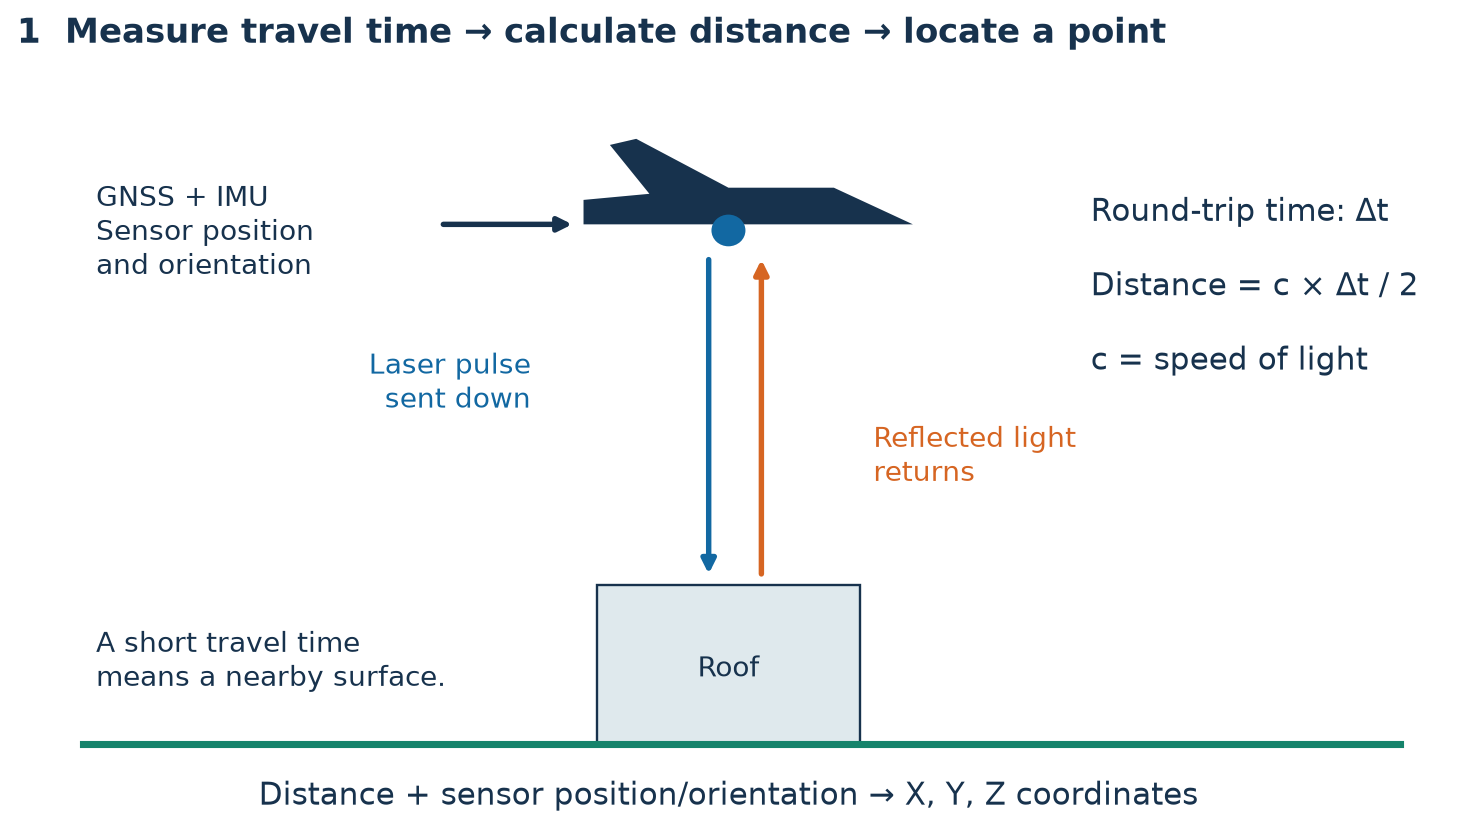

*Laser ranging measures distance; positioning and orientation turn that distance into coordinates.*


### Why can one pulse have several returns?

Parts of a pulse may reflect from leaves, branches, and the ground at different times. These can be recorded as separate returns. The first return is often near the top of a surface; a last return is not automatically ground. Some pulses produce only one return, and dense cover may prevent a ground return. [NOAA LiDAR 101](https://coast.noaa.gov/data/digitalcoast/pdf/lidar-101.pdf) explains these concepts.


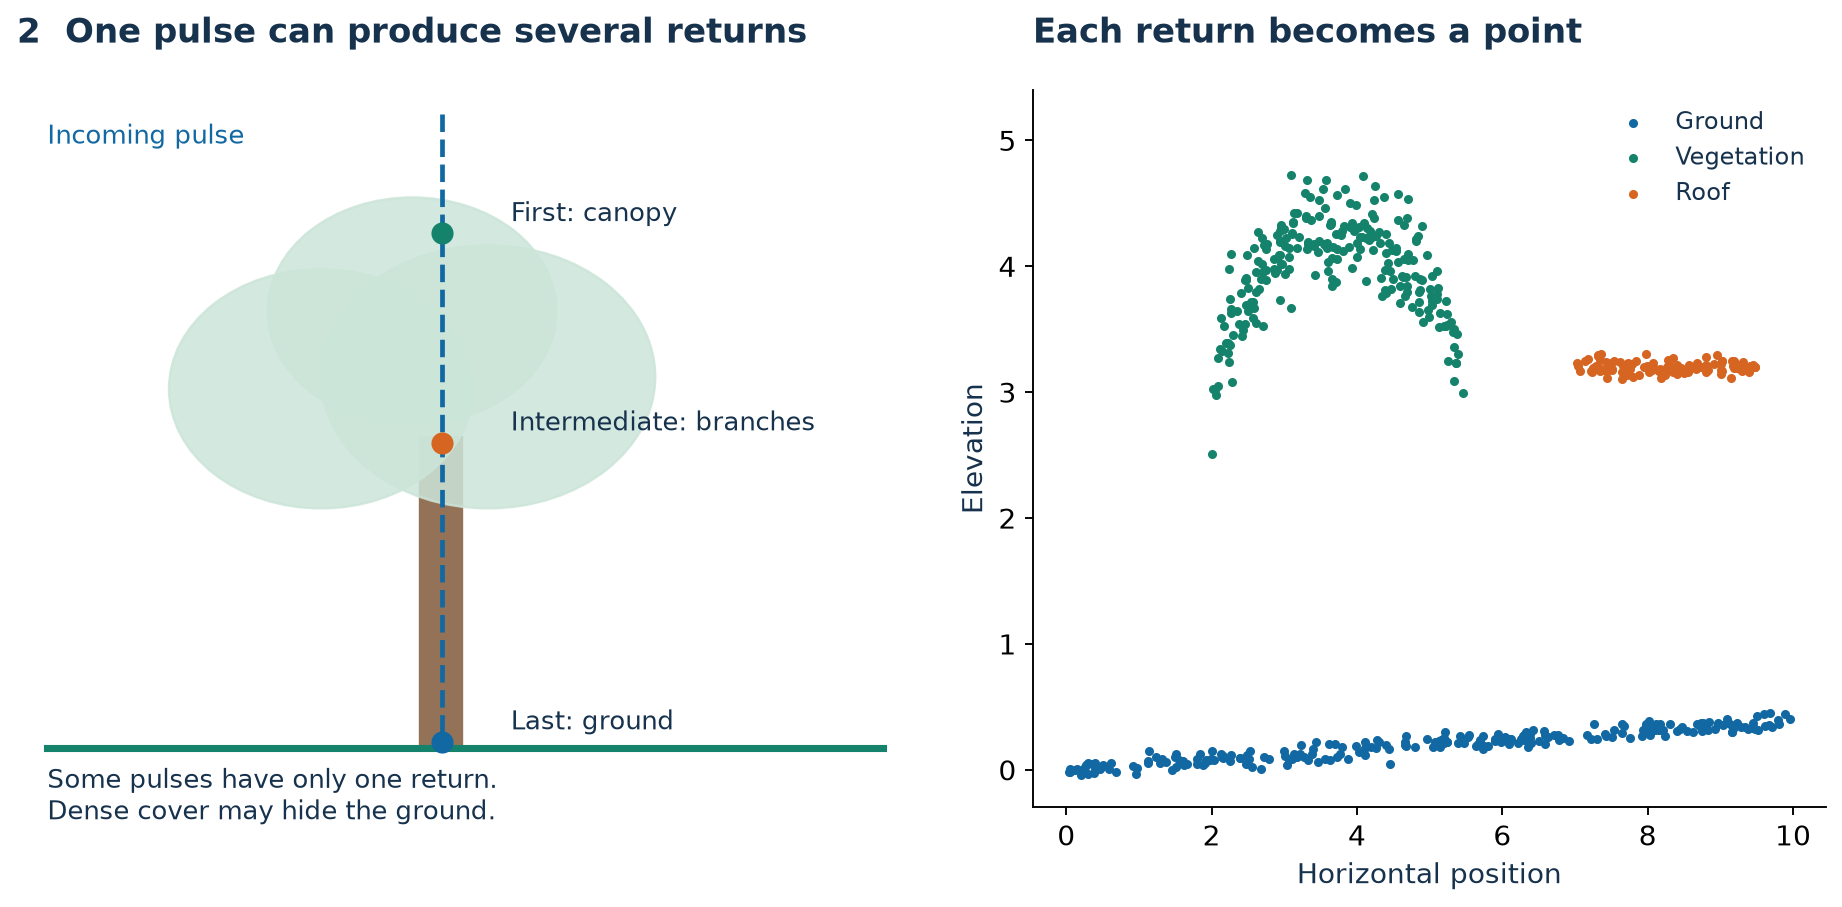

*A point cloud contains discrete returns. Return order and surface classification describe different things.*


### What is inside a LAS file?

**LAS** is a common binary point-cloud format. **LAZ** is a losslessly compressed form. PDAL reads both when the required format support is installed.

| Attribute | What it tells us |
| --- | --- |
| X, Y, Z | Position and elevation in the file's coordinate system |
| Return number | Whether this is the first, intermediate, or last recorded return of a pulse |
| Number of returns | How many returns were recorded for that pulse |
| Classification | An assigned label such as ground, vegetation, building, or noise |
| Intensity | Strength of the returned signal; not the same as a photograph's brightness |
| CRS and units | How to interpret coordinates and elevations |

A point cloud is irregularly spaced. Before interpreting elevations, inspect the coordinate reference system, units, and available ground classifications.

### DSM, DTM, and height above ground

- **DSM — digital surface model:** represents the top surface, including roofs and trees.
- **DTM — digital terrain model:** represents the ground beneath buildings and vegetation.
- **Height above ground:** can be estimated from DSM − DTM when grids, units, and vertical references match.

This tutorial creates a DSM. It does not produce a terrain model or directly measure building heights.


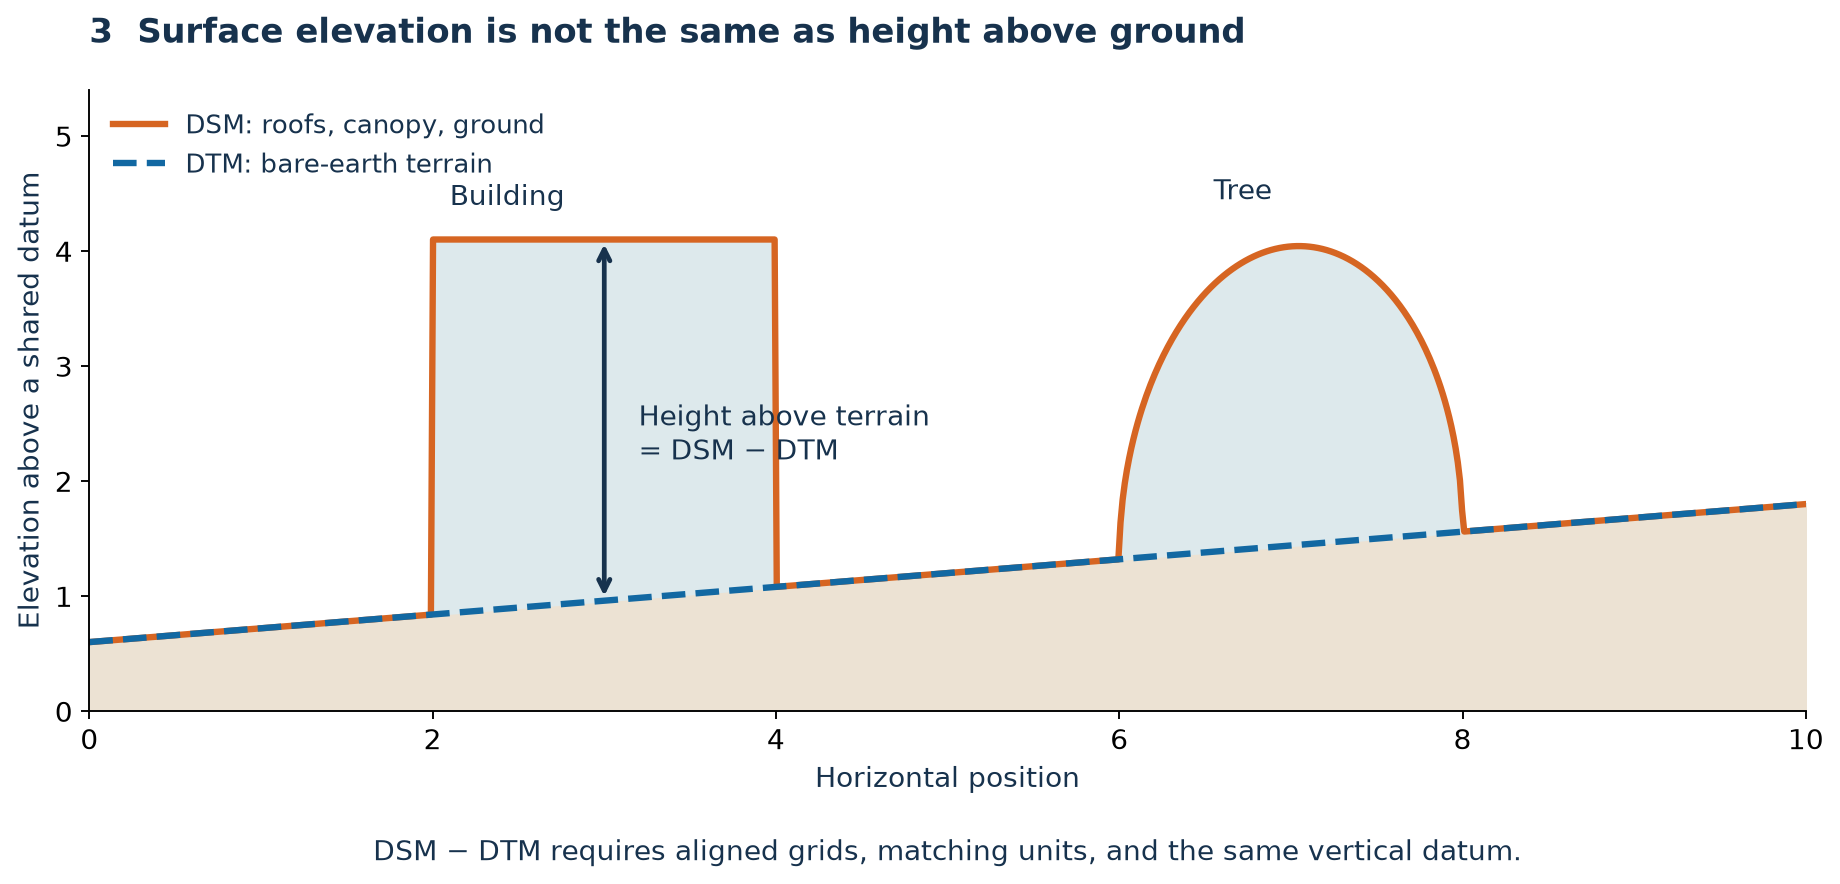

*Elevation above a datum and height above local terrain are different quantities.*


### From points to pixels

Rasterization assigns an elevation to each grid cell using nearby returns. A maximum is sensitive to isolated high points. Interpolation and a small median filter can reduce speckle, but may also reduce small structures and canopy peaks. We retain the raw and smoothed results for comparison.


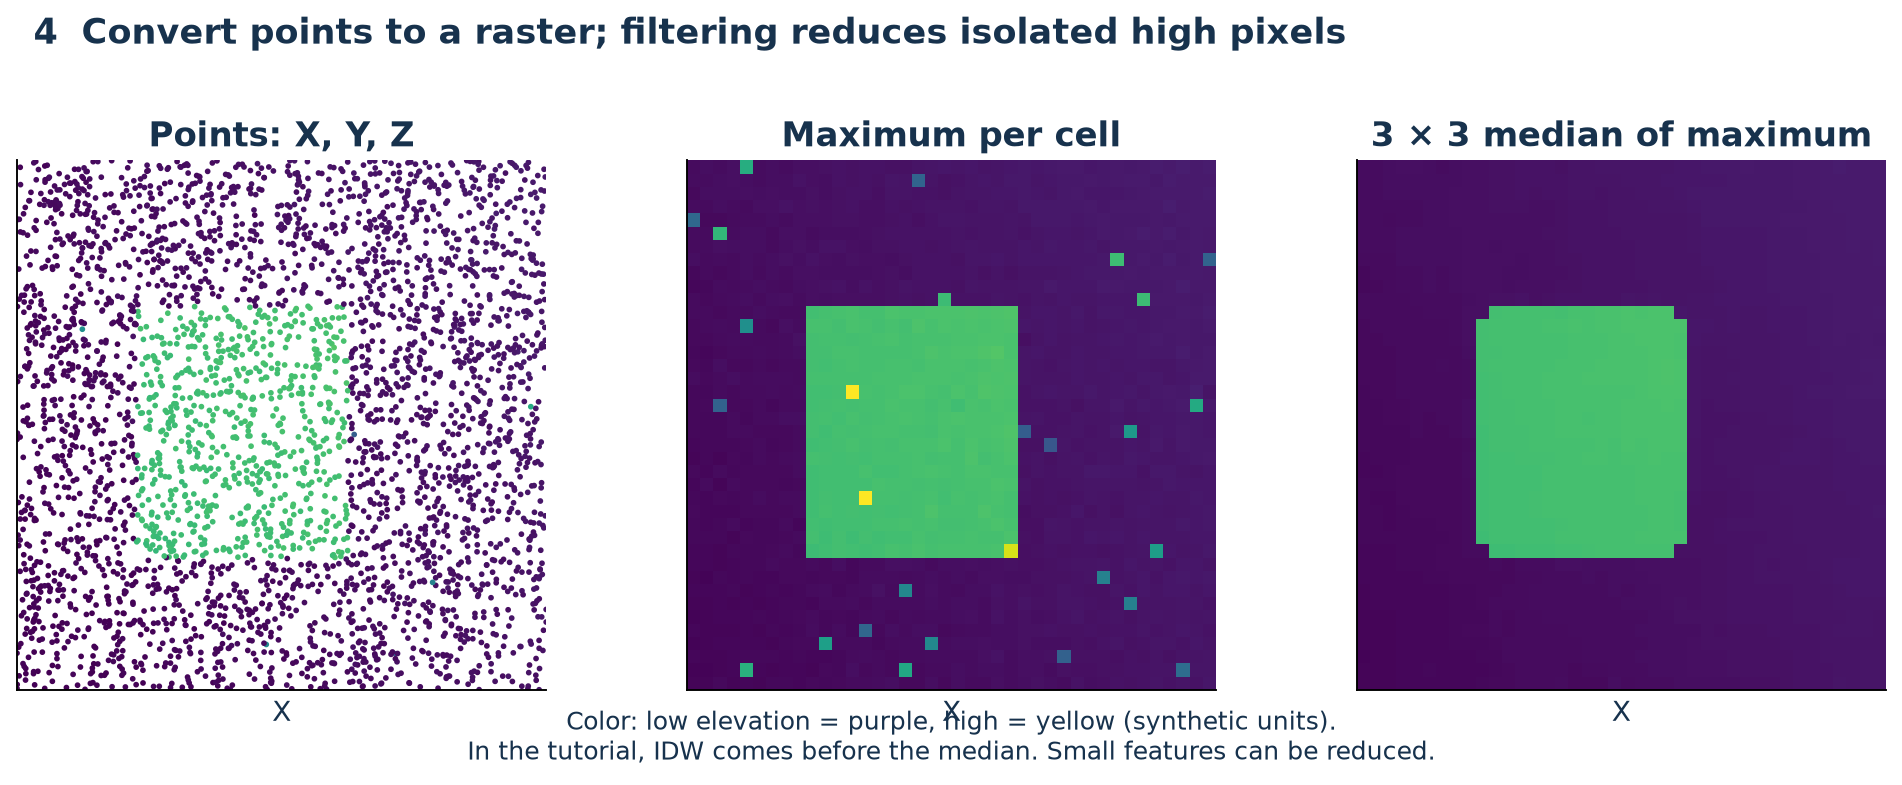

*Synthetic teaching example. The processing section below uses IDW interpolation followed by a median filter.*


## Before you start

Use **Python (largeviz)** for all three sections. Download <a href="environment-viz.yml" download>environment-viz.yml</a> beside the notebooks. In a terminal opened in this lab folder:

```bash
# First time only:
conda env create -f environment-viz.yml
# If largeviz already exists, update it instead:
# conda env update -n largeviz -f environment-viz.yml
conda activate largeviz
python -m ipykernel install --user --name largeviz --display-name "Python (largeviz)"
jupyter lab
```

In VS Code, open the notebook and select **Python (largeviz)**. Run the cells from top to bottom. See the [README](README.md) for setup troubleshooting.


## Download and save the LiDAR files

1. Create a folder named `week11` on your computer (or use the folder from Lecture 11A). Save <a href="lecture-11B.ipynb" download>lecture-11B.ipynb</a> and <a href="environment-viz.yml" download>environment-viz.yml</a> in it.
2. Inside `week11`, create a `data` folder, then a `lidar` folder inside it.
3. Download **both** LAS files using the direct links below, **or use the optional Python downloader in the next section**. Save them in `data/lidar/` and keep their original filenames. If clicking a link does not download it, right-click and choose **Save Link As…**.

| Case study | Direct download | Size |
| --- | --- | --- |
| University City | [Download Philadelphia_394.las](https://www.pasda.psu.edu/download/phillyLiDAR/2022/LAS/Classified_LAS/Philadelphia_394.las) | about 1.09 GB |
| Center City | [Download Philadelphia_456.las](https://www.pasda.psu.edu/download/phillyLiDAR/2022/LAS/Classified_LAS/Philadelphia_456.las) | about 997 MB |

Wait for both downloads to finish before running the notebook. These are `.las` files; **no extraction is needed**. Allow at least 3 GB of free space for the data and results.

```text
week11/
├── lecture-11B.ipynb
├── environment-viz.yml
└── data/
    └── lidar/
        ├── Philadelphia_394.las
        └── Philadelphia_456.las
```

Open the notebook from this folder and select **Python (largeviz)**. All paths below are relative to the notebook's folder. If you saved the LAS files somewhere else, edit the two paths in Step 2.



## Optional: Download the same LAS files with Python

You can use this instead of clicking the links. It sends an **HTTP GET** request to PASDA's file URLs; PASDA's directory is a direct file service, not a catalog search API. The next optional section demonstrates a search API.

The function streams the response to `data/lidar/` in chunks so the whole file does not enter memory. It writes a temporary `.part` file, checks its size and LAS header, and renames it after a complete download. Existing complete files are reused.

Set `DOWNLOAD_PASDA = True` to download the two class files. Leave it `False` if you downloaded them manually. No API key is needed. The two files total about **2.09 GB**.


In [7]:
from pathlib import Path
import requests

def download_las_file(url, destination, expected_bytes=None):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists() and (expected_bytes is None or destination.stat().st_size == expected_bytes):
        print("Already saved:", destination.name)
        return destination

    temporary = destination.with_suffix(destination.suffix + ".part")
    print("Downloading:", destination.name)
    with requests.get(url, stream=True, timeout=(30, 180)) as response:
        response.raise_for_status()
        header_size = response.headers.get("Content-Length")
        with temporary.open("wb") as stream:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    stream.write(chunk)
    size = temporary.stat().st_size
    required_size = expected_bytes if expected_bytes is not None else (int(header_size) if header_size else None)
    if required_size is not None and size != required_size:
        raise ValueError("Incomplete download. Rerun this cell to try again.")
    with temporary.open("rb") as stream:
        if stream.read(4) != b"LASF":
            raise ValueError("The response is not a LAS/LAZ file. Check the download URL.")
    temporary.replace(destination)
    print(f"Saved {size / 1e6:,.1f} MB:", destination)
    return destination


In [10]:
DOWNLOAD_PASDA = True  # Change to True to download the class data.
base_url = "https://www.pasda.psu.edu/download/phillyLiDAR/2022/LAS/Classified_LAS/"
files = {"Philadelphia_394.las": 1_090_289_145,
         "Philadelphia_456.las": 997_092_345}

if DOWNLOAD_PASDA:
    for filename, size in files.items():
        download_las_file(base_url + filename, Path("data/lidar") / filename, size)
else:
    print("Use the download links above, or set DOWNLOAD_PASDA = True.")


Downloading: Philadelphia_394.las
Saved 1,090.3 MB: data/lidar/Philadelphia_394.las
Downloading: Philadelphia_456.las
Saved 997.1 MB: data/lidar/Philadelphia_456.las


## Optional extension: Search the USGS API for other LiDAR data

The [USGS TNMAccess API](https://www.usgs.gov/faqs/there-api-accessing-national-map-data) provides a searchable catalog. The pattern is **request metadata → inspect results → download a selected file**. [API documentation](https://tnmaccess.nationalmap.gov/api/v1/docs).

The example searches a small Philadelphia bounding box. `bbox` uses **west, south, east, north in longitude/latitude**, not State Plane feet. `max=3` limits this response; additional results require pagination using `offset`. The response contains `items` with a `downloadURL` for each product. No API key is needed for this example.

Set `SEARCH_USGS = True` to make the metadata request. Returned products can change. This extension may return LAZ files from different surveys; keep using the two PASDA files for the DSM workflow below, whose bounds and CRS checks are specific to those files.


In [11]:
SEARCH_USGS = False  # Metadata only; does not download point clouds.
products = []

if SEARCH_USGS:
    response = requests.get(
        "https://tnmaccess.nationalmap.gov/api/v1/products",
        params={
            "datasets": "Lidar Point Cloud (LPC)",
            "bbox": "-75.18,39.94,-75.15,39.96",
            "max": 3,
            "offset": 0,
            "outputFormat": "JSON",
        },
        timeout=60,
    )
    response.raise_for_status()
    catalog = response.json()
    if catalog.get("error"):
        raise RuntimeError(catalog["error"])
    products = catalog.get("items", [])
    print("Total matching products:", catalog.get("total"))
    for index, product in enumerate(products):
        print(index, product.get("title"), product.get("format"))
        print("  Download:", product.get("downloadURL"))
else:
    print("Set SEARCH_USGS = True to search the USGS catalog.")


Set SEARCH_USGS = True to search the USGS catalog.


### Download one selected USGS result

Inspect the titles and metadata before choosing an index. This optional cell saves the selected file to a separate `data/lidar/usgs/` folder; it does not substitute it into the class workflow.


In [12]:
DOWNLOAD_USGS = False  # May download a large file.
selected_index = 0

if DOWNLOAD_USGS:
    if not products:
        raise ValueError("Run the USGS search first and inspect the results.")
    from urllib.parse import urlsplit, unquote
    product = products[selected_index]
    url = product["downloadURL"]
    filename = Path(unquote(urlsplit(url).path)).name
    download_las_file(url, Path("data/lidar/usgs") / filename)


## 1. Import processing packages and set the output folder

Continue here after both class LAS files are saved in `data/lidar/`.


In [13]:
from pathlib import Path
import json
import math

import pdal
import rasterio
from rasterio.plot import show
from pyproj import CRS
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

OUT = Path("outputs/lidar/case_studies")
OUT.mkdir(parents=True, exist_ok=True)
print("PDAL:", pdal.__version__)


PDAL: 3.5.3


## 2. Open your downloaded files

These PASDA tiles cover approximately 914 × 914 m each. They are case studies, not complete neighborhood coverage. The bounds below select the corresponding footprints in the source coordinate system.


In [14]:
cases = [
    {"zone": "University City", "name": "Philadelphia_394.las",
     "bounds": [2685000, 235000, 2688000, 238000]},
    {"zone": "Center City", "name": "Philadelphia_456.las",
     "bounds": [2691000, 235000, 2694000, 238000]},
]
pd.DataFrame(cases)[["zone", "name"]]

,zone,name
0,University City,Philadelphia_394.las
1,Center City,Philadelphia_456.las


Set the paths to the files you downloaded. If you see `FileNotFoundError` in the next step, check that the files are in `data/lidar/` beside this notebook and that their names match exactly.


In [15]:
las_paths = [
    Path("data/lidar/Philadelphia_394.las"),
    Path("data/lidar/Philadelphia_456.las"),
]


## 3. Check the coordinate system and units

Read the LAS header with `quickinfo`. Keep the native horizontal CRS and convert Z to meters using its vertical CRS. Convert the **1 m** pixel size to the horizontal coordinate units too. This changes units, not the vertical datum.


In [16]:
infos = []
for path in las_paths:
    reader = pdal.Pipeline(json.dumps([{"type": "readers.las", "filename": str(path)}]))
    header = reader.quickinfo["readers.las"]
    crs = CRS.from_wkt(header["metadata"]["srs"]["compoundwkt"])
    if not crs.is_compound:
        raise ValueError("Expected a horizontal + vertical CRS; inspect the LAS metadata.")
    horizontal, vertical = crs.sub_crs_list[:2]
    if horizontal.is_bound:
        horizontal = horizontal.source_crs
    if not horizontal.is_projected:
        raise ValueError("Expected projected XY coordinates.")
    infos.append({"points": header["num_points"],
                  "horizontal": horizontal, "vertical": vertical,
                  "xy_to_m": horizontal.axis_info[0].unit_conversion_factor,
                  "z_to_m": vertical.axis_info[0].unit_conversion_factor})

pd.DataFrame([{"zone": case["zone"], "points": info["points"],
               "horizontal_crs": info["horizontal"].name,
               "xy_units": info["horizontal"].axis_info[0].unit_name,
               "vertical_crs": info["vertical"].name,
               "z_units": info["vertical"].axis_info[0].unit_name}
              for case, info in zip(cases, infos)])

,zone,points,horizontal_crs,xy_units,vertical_crs,z_units
0,University City,36291327,NAD83(2011) / Pennsylvania South (ftUS),US Survey Foot,NAVD88 height (ftUS) - US Geoid Model of 2018,US Survey Foot
1,Center City,33187641,NAD83(2011) / Pennsylvania South (ftUS),US Survey Foot,NAVD88 height (ftUS) - US Geoid Model of 2018,US Survey Foot


## 4. Create raw DSM rasters

Keep first returns and exclude classified noise and withheld points. Compare two ways to rasterize the same points:

- **Maximum:** the highest return in each pixel; sensitive to individual high points.
- **IDW:** a distance-weighted average within **1.5 m** of each cell center; a smoother estimated surface.

A small radius limits mixing across roofs and streets. No extra gap filling is applied. See [PDAL's GDAL writer](https://pdal.io/en/stable/stages/writers.gdal.html).


In [17]:
CELL_SIZE_M = 1.0
NODATA = -9999.0

def make_dsm_pipeline(path, case, info, destination, method="idw"):
    resolution = CELL_SIZE_M / info["xy_to_m"]
    left, bottom, right, top = case["bounds"]
    origin_x = math.floor(left / resolution) * resolution
    origin_y = math.floor(bottom / resolution) * resolution
    return {"pipeline": [
        {"type": "readers.las", "filename": str(path)},
        {"type": "filters.crop", "bounds": f"([{left},{right}],[{bottom},{top}])"},
        {"type": "filters.expression", "expression":
         "ReturnNumber == 1 && Classification != 7 && Classification != 18 && Withheld == 0"},
        {"type": "filters.assign", "value": f"Z = Z * {info['z_to_m']:.15g}"},
        {"type": "writers.gdal", "filename": str(destination),
         "resolution": resolution, "origin_x": origin_x, "origin_y": origin_y,
         "width": math.floor((right-origin_x)/resolution) + 1,
         "height": math.floor((top-origin_y)/resolution) + 1,
         "output_type": method, "binmode": method == "max",
         "radius": 1.5 * resolution, "window_size": 0,
         "data_type": "float32", "nodata": NODATA,
         "override_srs": info["horizontal"].to_wkt(),
         "gdalopts": "COMPRESS=DEFLATE,TILED=YES"},
    ]}



In [18]:
raw_paths = []
max_paths = []
for path, case, info in zip(las_paths, cases, infos):
    for method in ["max", "idw"]:
        destination = OUT / f"{path.stem}_{method}.tif"
        specification = make_dsm_pipeline(path, case, info, destination, method)
        destination.with_suffix(".json").write_text(json.dumps(specification, indent=2))
        pipeline = pdal.Pipeline(json.dumps(specification))
        pipeline.execute_streaming(chunk_size=250_000)
        with rasterio.open(destination, "r+") as dst:
            dst.set_band_unit(1, "m")
            dst.update_tags(vertical_reference=info["vertical"].name, method=method)
        (max_paths if method == "max" else raw_paths).append(destination)
        print(case["zone"], method, "→", destination.name)


University City max → Philadelphia_394_max.tif
University City idw → Philadelphia_394_idw.tif
Center City max → Philadelphia_456_max.tif
Center City idw → Philadelphia_456_idw.tif


## 5. Remove isolated pixels with a median filter

A **3 × 3 median** replaces each pixel with its neighborhood median. It reduces speckle while retaining broad roof edges better than a blur. It can remove small roof features and canopy peaks, so keep both raw rasters for analysis.

Temporarily use nearest valid values so NoData cannot contaminate the filter, then restore the exact IDW NoData mask. We leave remaining gaps and water unfilled.


In [19]:
from scipy.ndimage import distance_transform_edt, median_filter

dsm_paths = []
for path in raw_paths:
    with rasterio.open(path) as src:
        data = src.read(1, masked=True)
        valid = ~np.ma.getmaskarray(data)
        nearest = distance_transform_edt(~valid, return_distances=False, return_indices=True)
        smooth = median_filter(data.data[tuple(nearest)], size=3, mode="nearest")
        smooth[~valid] = src.nodata
        profile = src.profile.copy()
        tags = src.tags()
    destination = path.with_name(path.stem.replace("_idw", "_dsm") + ".tif")
    with rasterio.open(destination, "w", **profile) as dst:
        dst.write(smooth.astype("float32"), 1)
        dst.set_band_unit(1, "m")
        dst.update_tags(**tags, smoothing="3x3 median; IDW NoData mask retained")
    destination.with_suffix(".json").write_text(json.dumps({
        "source_raster": path.name, "source_pipeline": path.with_suffix(".json").name,
        "smoothing": "3x3 median", "preserve_nodata": True
    }, indent=2))
    dsm_paths.append(destination)
    print(destination.name)


Philadelphia_394_dsm.tif
Philadelphia_456_dsm.tif


## 6. Compare before and after

The same central 250 × 250 pixel window and color scale show maximum, IDW, and smoothed IDW for each tile. The GeoTIFFs keep elevation values in meters; color limits affect only the plots.


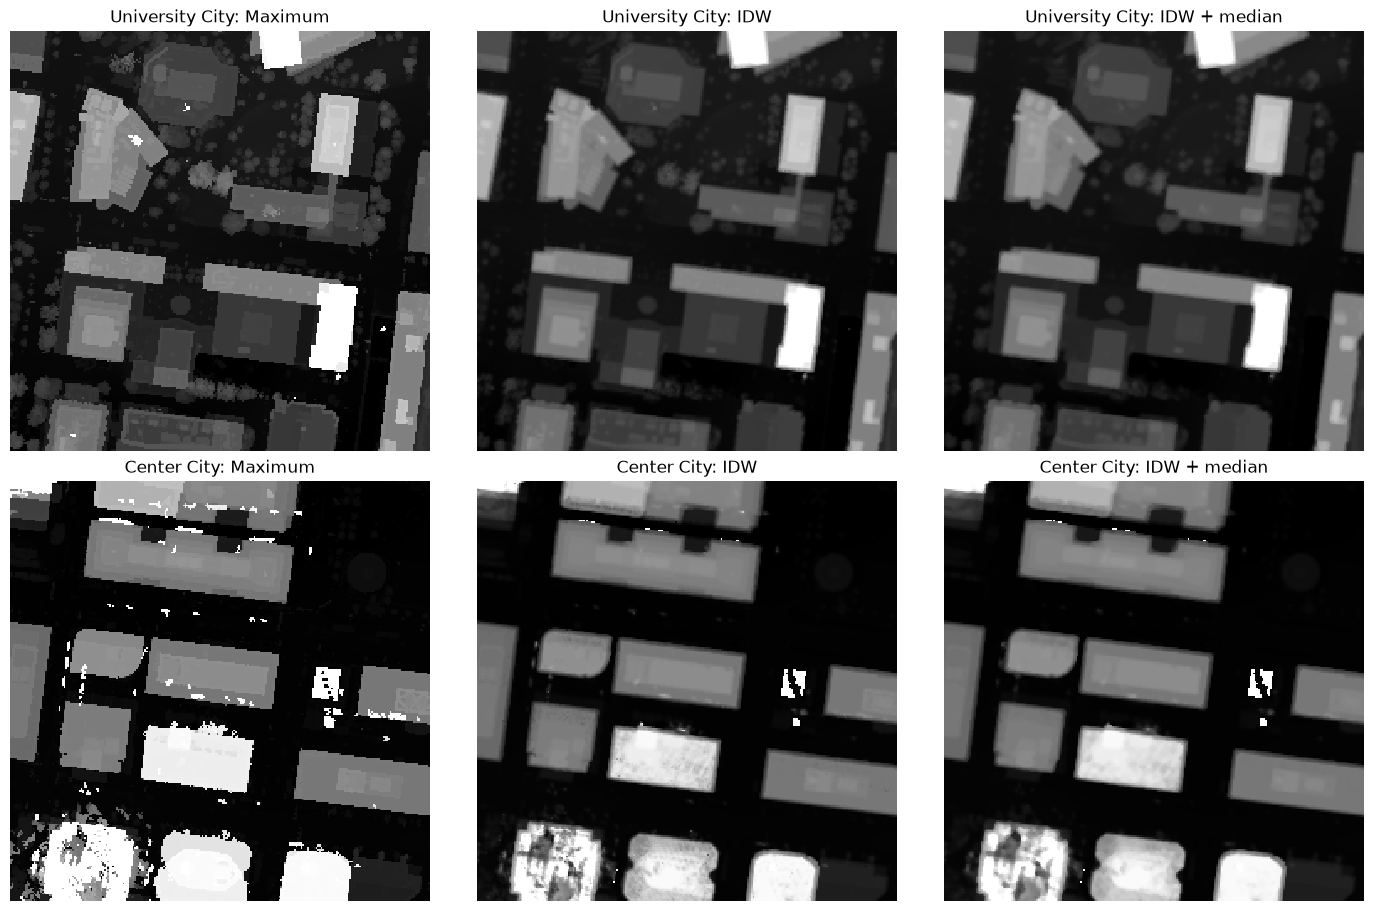

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(14, 9), constrained_layout=True)
for row, (case, paths) in enumerate(zip(cases, zip(max_paths, raw_paths, dsm_paths))):
    windows = []
    for path in paths:
        with rasterio.open(path) as src:
            r, c = src.height // 2, src.width // 2
            windows.append(src.read(1, masked=True)[r-125:r+125, c-125:c+125])
    low, high = np.percentile(np.concatenate([a.compressed() for a in windows]), [2, 98])
    for ax, data, title in zip(axes[row], windows, ["Maximum", "IDW", "IDW + median"]):
        ax.imshow(data, cmap="gray", vmin=low, vmax=high, interpolation="nearest")
        ax.set_title(f"{case['zone']}: {title}")
        ax.set_axis_off()
fig.savefig(OUT / "dsm_before_after.png", dpi=160)
plt.show()


### Check and plot the final DSMs

Check CRS, pixel size, coverage, and elevation range. Both maps below use one elevation scale.


In [21]:
summary = []
rasters = []
for path, case, info in zip(dsm_paths, cases, infos):
    with rasterio.open(path) as src:
        data = src.read(1, masked=True)
        assert src.count == 1 and src.crs == info["horizontal"]
        assert np.isclose(src.res[0] * info["xy_to_m"], CELL_SIZE_M)
        assert data.count() > 0
        rasters.append((data, src.transform))
        summary.append({"zone": case["zone"], "shape": data.shape,
                        "pixel_size_m": src.res[0] * info["xy_to_m"],
                        "valid_percent": 100 * data.count() / data.size,
                        "min_m": float(data.min()), "max_m": float(data.max())})
pd.DataFrame(summary)

,zone,shape,pixel_size_m,valid_percent,min_m,max_m
0,University City,"(915, 916)",1.0,99.879256,-1.358158,174.683121
1,Center City,"(915, 915)",1.0,99.776524,2.210053,308.403564


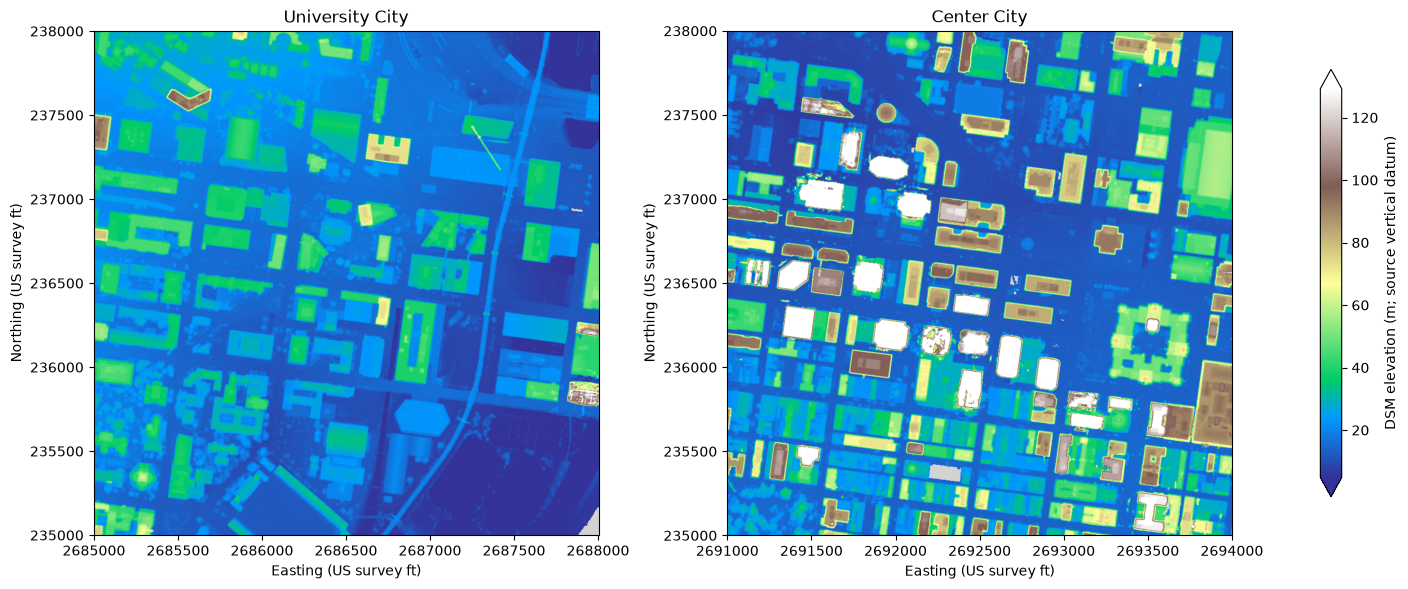

In [23]:
values = np.concatenate([data.compressed() for data, transform in rasters])
vmin, vmax = np.percentile(values, [2, 98])
norm = Normalize(vmin=vmin, vmax=max(vmax, vmin + 1))
cmap = plt.colormaps["terrain"].copy()
cmap.set_bad("lightgray")
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)
for ax, case, (data, transform) in zip(axes, cases, rasters):
    show(data, transform=transform, ax=ax, cmap=cmap, norm=norm, adjust=False)
    ax.set(title=case["zone"], xlabel="Easting (US survey ft)", ylabel="Northing (US survey ft)")
    ax.ticklabel_format(style="plain", useOffset=False)
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes,
             label="DSM elevation (m; source vertical datum)", shrink=0.75, extend="both")
fig.savefig(OUT / "center_city_university_city_dsm.png", dpi=160)
plt.show()

## Try it yourself

1. Change `CELL_SIZE_M` to 2 and rerun from Step 4. Compare roof detail and speckle.
2. Compare the raw maximum and smoothed surfaces. Which small features disappear?
3. Why do you need a terrain model to estimate building heights?

**Outputs:** `_max.tif` (raw maximum), `_idw.tif` (raw interpolation), and `_dsm.tif` (smoothed surface), plus pipeline JSONs and comparison figures in `outputs/lidar/case_studies/`. Keep raw and smoothed surfaces separate when measuring heights.
